In [1]:
import pandas as pd

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [2]:
df.dtypes

ID                            int64
text                         object
polarity                     object
favorite_count                int64
retweet_count                 int64
user_followers_count          int64
user_friends_count            int64
user_favourites_count         int64
user_statuses_count           int64
user_verified                 int64
user_has_extended_profile     int64
user_is_translator            int64
user_protected                int64
user_default_profile          int64
dtype: object

In [3]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [4]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [5]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [6]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


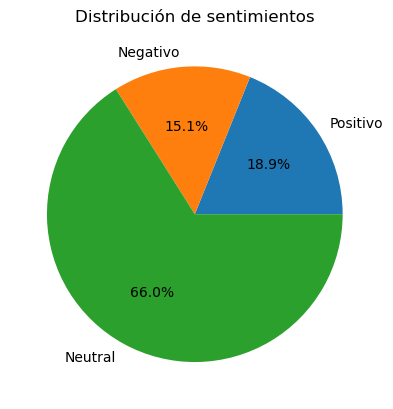

In [7]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


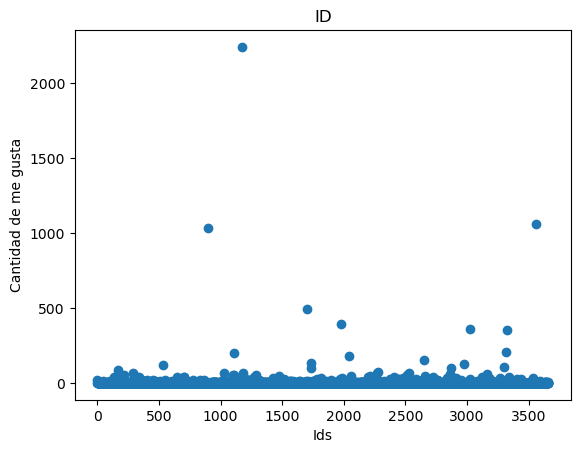

In [8]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


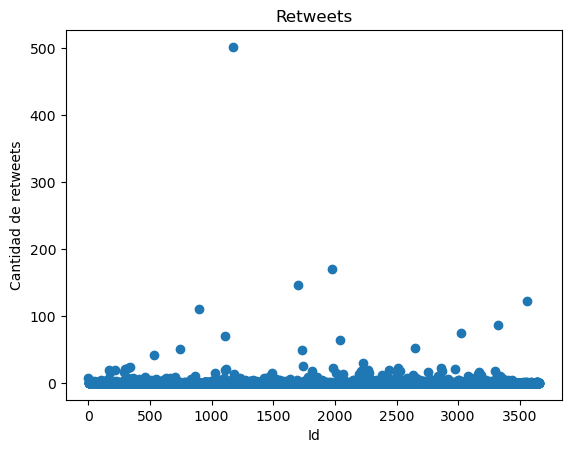

In [9]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


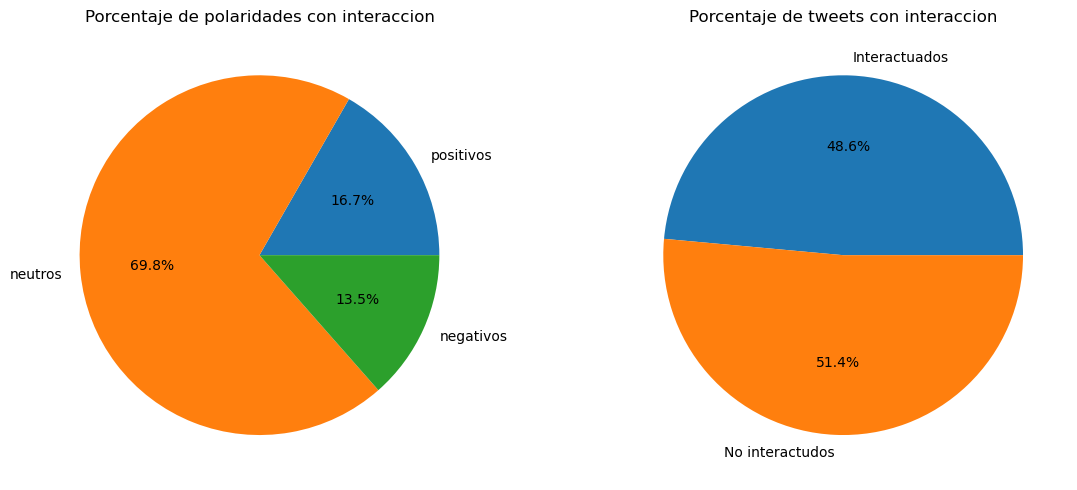

In [10]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [11]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [12]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [14]:
from sklearn.preprocessing import StandardScaler

number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count"]

scaler = StandardScaler()

X_train[number_columns] = scaler.fit_transform(X_train[number_columns])

# y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

X_train.head()
y_train.head()

1468    NEU
3145    NEU
2137    NEU
3883    NEU
2562    NEU
Name: polarity, dtype: object

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Inicializamos dentro de transform para evitar errores de multiprocessing
        stop_words = set(stopwords.words('spanish'))
        punctuation = set(string.punctuation)
        stemmer = PorterStemmer()
        lemmatizer = WordNetLemmatizer()

        clean_X = []
        for text in X:
            # 1. Minúsculas y Tokenización
            tokens = nltk.word_tokenize(text.lower())

            # 2. Remover Stopwords y Puntuación
            tokens = [t for t in tokens if t not in stop_words and t not in punctuation]

            # 3. Reducción a raíz (Stemming o Lemmatization)
            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [lemmatizer.lemmatize(t) for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ianra\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ianra\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ianra\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [17]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model.encode(list(X), show_progress_bar=False)

embedding = EmbeddingTransformer()

In [18]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])
print(text.shape)
print(text)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(3660, 384)
[[-0.02724164  0.10455129 -0.04723523 ... -0.01374261  0.02333486
  -0.00313624]
 [-0.03370526 -0.03248617 -0.03679636 ...  0.0900555   0.06545153
  -0.09212548]
 [ 0.01644317 -0.01165346 -0.03747016 ...  0.06008791  0.00592147
  -0.03181845]
 ...
 [ 0.02163995 -0.02315095 -0.09253237 ...  0.04938937 -0.03362131
   0.02800951]
 [-0.01722544  0.04379563  0.04499667 ...  0.1241366  -0.01925775
  -0.08086784]
 [ 0.0486871  -0.02563934 -0.00477339 ...  0.04169149 -0.02811955
  -0.03216958]]


## Logistic Regression - BoW y TF-IDF

In [19]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_recall_curve,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import label_binarize

RANDOM_STATE = 42

print("Tweets (train, val, test)", (len(X_train), len(X_val), len(X_test)))

preprocesador = ColumnTransformer([
    ("texto", Pipeline([
        ("limpieza", TextCleaner()),
        ("vectorizador", TfidfVectorizer()),
    ]), "text"),
])

pipeline_lr = Pipeline([
    ("preprocesador", preprocesador),
    ("clasificador", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

param_grid_lr = [
    {
        "preprocesador__texto__limpieza__method": [None, "stem"],
        "preprocesador__texto__vectorizador": [TfidfVectorizer()],
        "preprocesador__texto__vectorizador__ngram_range": [(1, 1), (1, 2)],
        "clasificador__C": [0.5, 1.0],
        "clasificador__class_weight": [None, "balanced"],
    },
    {
        "preprocesador__texto__limpieza__method": [None, "stem"],
        "preprocesador__texto__vectorizador": [CountVectorizer()],
        "preprocesador__texto__vectorizador__ngram_range": [(1, 1), (1, 2)],
        "clasificador__C": [0.5, 1.0],
        "clasificador__class_weight": [None, "balanced"],
    },
]

metricas = {"f1_macro": "f1_macro", "roc_auc_ovr": "roc_auc_ovr"}

grid_lr = GridSearchCV(
    pipeline_lr,
    param_grid_lr,
    cv=3,
    scoring=metricas,
    refit="f1_macro",
    n_jobs=1,
    verbose=1,
)
grid_lr.fit(X_train, y_train)

print("Mejores parámetros:", grid_lr.best_params_)
print("F1 macro (CV):", grid_lr.cv_results_["mean_test_f1_macro"][grid_lr.best_index_])
print("ROC-AUC OvR (CV):", grid_lr.cv_results_["mean_test_roc_auc_ovr"][grid_lr.best_index_])

Tweets (train, val, test) (2196, 732, 732)
Fitting 3 folds for each of 32 candidates, totalling 96 fits
Mejores parámetros: {'clasificador__C': 1.0, 'clasificador__class_weight': 'balanced', 'preprocesador__texto__limpieza__method': 'stem', 'preprocesador__texto__vectorizador': TfidfVectorizer(), 'preprocesador__texto__vectorizador__ngram_range': (1, 1)}
F1 macro (CV): 0.5539458782780837
ROC-AUC OvR (CV): 0.7543036834933049


## Logistic Regression - Embeddings

In [20]:
embedding_multi = EmbeddingTransformer(model_name="paraphrase-multilingual-mpnet-base-v2")
embedding_multi.fit(X_train["text"]) 

emb_train = embedding_multi.transform(X_train["text"])
emb_val = embedding_multi.transform(X_val["text"])
emb_test = embedding_multi.transform(X_test["text"])


param_grid_emb = {
    "C": [0.03, 0.1, 0.3, 1.0],
    "class_weight": [None, "balanced"],
}
grid_emb = GridSearchCV(
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    param_grid_emb,
    cv=3,
    scoring=metricas,
    refit="f1_macro",
    n_jobs=1,
    verbose=1,
)
grid_emb.fit(emb_train, y_train)

best_index_emb = grid_emb.best_index_
print("Mejores parámetros:", grid_emb.best_params_)
print("F1 macro (CV):", grid_emb.cv_results_["mean_test_f1_macro"][best_index_emb])
print("ROC-AUC OvR (CV):", grid_emb.cv_results_["mean_test_roc_auc_ovr"][best_index_emb])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores parámetros: {'C': 1.0, 'class_weight': None}
F1 macro (CV): 0.6932214431839885
ROC-AUC OvR (CV): 0.8837462500808155


## Comparación en validación

In [ ]:
def metricas(y_real, predicciones, probabilidades, clases):
    return {
        "Accuracy": accuracy_score(y_real, predicciones),
        "F1 macro": f1_score(y_real, predicciones, average="macro"),
        "ROC-AUC OvR": roc_auc_score(
            y_real, probabilidades, labels=clases, multi_class="ovr", average="macro"
        ),
    }

resultados_validacion = {
    "BoW / TF-IDF": metricas(
        y_val,
        grid_lr.predict(X_val),
        grid_lr.predict_proba(X_val),
        grid_lr.classes_,
    ),
    "Embeddings": metricas(
        y_val,
        grid_emb.predict(emb_val),
        grid_emb.predict_proba(emb_val),
        grid_emb.classes_,
    ),
}
tabla_validacion = pd.DataFrame(resultados_validacion).T.sort_values(
    "F1 macro", ascending=False
)
print(tabla_validacion.round(4))
print("Modelo elegido por F1 macro:", tabla_validacion.index[0])

              Accuracy  F1 macro  ROC-AUC OvR
Embeddings      0.7705    0.6946       0.8860
BoW / TF-IDF    0.6858    0.6054       0.7859
Modelo elegido por F1 macro: Embeddings


## Evaluación final en test

In [30]:
y_trainval = pd.concat([y_train, y_val])

modelo = grid_emb.best_estimator_
modelo.fit(np.vstack([emb_train, emb_val]), y_trainval)

y_pred = modelo.predict(emb_test)
y_proba = modelo.predict_proba(emb_test)


print("Modelo: Embeddings")
metricas_test = metricas(y_test, y_pred, y_proba, modelo.classes_)
print({nombre: round(valor, 4) for nombre, valor in metricas_test.items()})
print(classification_report(
    y_test, y_pred, zero_division=0, digits=3
))

Modelo: Embeddings
{'Accuracy': 0.776, 'F1 macro': 0.694, 'ROC-AUC OvR': 0.8795}
              precision    recall  f1-score   support

           N      0.687     0.518     0.591       110
         NEU      0.797     0.890     0.841       484
           P      0.741     0.580     0.650       138

    accuracy                          0.776       732
   macro avg      0.741     0.663     0.694       732
weighted avg      0.770     0.776     0.767       732



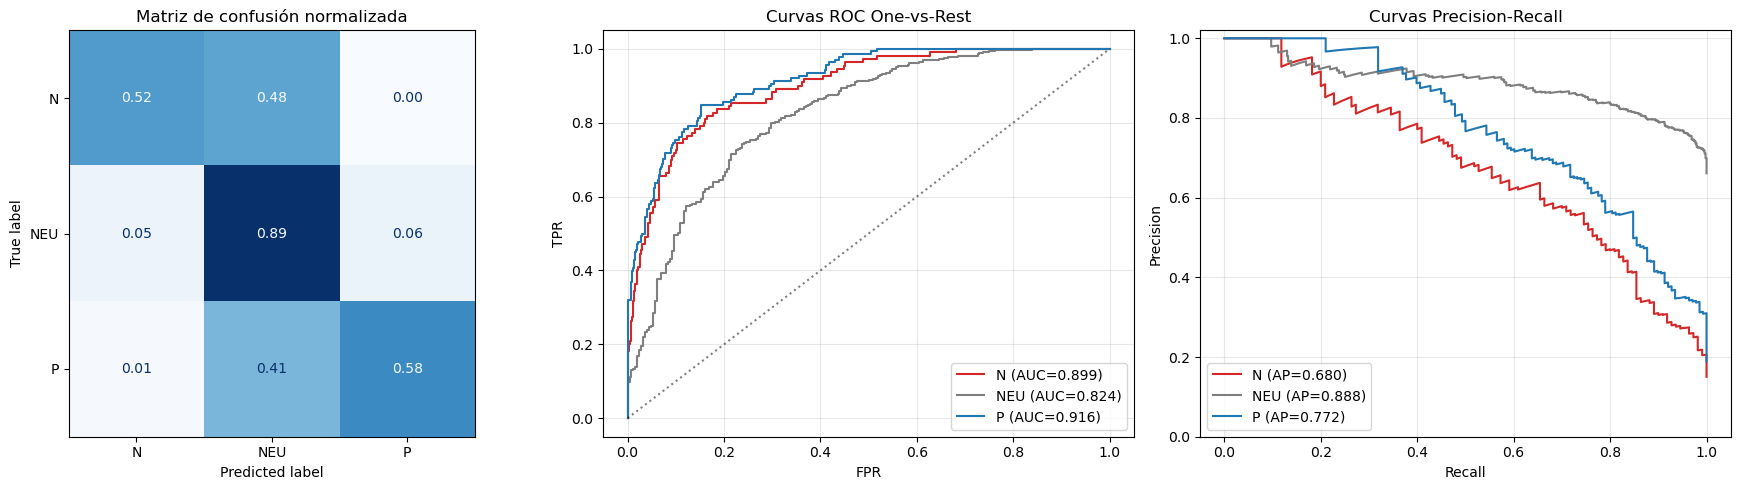

In [23]:
clases_modelo = modelo.classes_
y_test_bin = label_binarize(y_test, classes=clases_modelo)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=clases_modelo,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Matriz de confusión normalizada")

colores = ["tab:red", "tab:gray", "tab:blue"]
for indice, clase in enumerate(clases_modelo):
    fpr, tpr, _ = roc_curve(y_test_bin[:, indice], y_proba[:, indice])
    axes[1].plot(fpr, tpr, color=colores[indice],
                 label=f"{clase} (AUC={auc(fpr, tpr):.3f})")
    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, indice], y_proba[:, indice]
    )
    ap = average_precision_score(y_test_bin[:, indice], y_proba[:, indice])
    axes[2].plot(recall, precision, color=colores[indice],
                 label=f"{clase} (AP={ap:.3f})")

axes[1].plot([0, 1], [0, 1], "k:", alpha=0.5)
axes[1].set(title="Curvas ROC One-vs-Rest", xlabel="FPR", ylabel="TPR")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)
axes[2].set(title="Curvas Precision-Recall", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
axes[2].legend(loc="lower left")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
errores = pd.DataFrame({
    "texto": X_test["text"].to_numpy(),
    "real": y_test.to_numpy(),
    "predicho": y_pred,
    "confianza": y_proba.max(axis=1),
})
solo_errores = errores[errores["real"] != errores["predicho"]]

print("Errores por clase real -> predicha:")
print(solo_errores.groupby(["real", "predicho"]).size().sort_values(ascending=False).to_string())

Errores por clase real -> predicha:
real  predicho
P     NEU         57
N     NEU         53
NEU   P           28
      N           25
P     N            1


In [25]:
def predecir_tweet(texto):
    texto_crudo = pd.Series([texto])
    fila = pd.DataFrame({"text": texto_crudo})
    
    entrada = embedding_multi.transform(fila["text"])

    probabilidades = pd.Series(
        modelo.predict_proba(entrada)[0], index=modelo.classes_
    ).sort_values(ascending=False)
    print("Tweet:", texto)
    print("Predicción:", probabilidades.index[0])
    print(probabilidades.round(3).to_string())

predecir_tweet("La IA nos va a sacar el trabajo y encima lo hace mal!")
print()
predecir_tweet("Increíble lo que se puede hacer con ChatGPT, me ahorra horas de trabajo")
print()
predecir_tweet("Hoy se presentó una nueva herramienta de inteligencia artificial para empresas")

Tweet: La IA nos va a sacar el trabajo y encima lo hace mal!
Predicción: N
N      0.936
NEU    0.063
P      0.001

Tweet: Increíble lo que se puede hacer con ChatGPT, me ahorra horas de trabajo
Predicción: P
P      0.991
NEU    0.009
N      0.000

Tweet: Hoy se presentó una nueva herramienta de inteligencia artificial para empresas
Predicción: P
P      0.664
NEU    0.335
N      0.001


In [28]:
print(f"Mejor modelo (elegido en validación): {tabla_validacion.index[0]}")
print(f"  F1 macro en validación: {tabla_validacion.loc[tabla_validacion.index[0], 'F1 macro']:.3f}")
print(f"  F1 macro en test:       {metricas_test['F1 macro']:.3f}")
print(f"  ROC-AUC OvR en test:    {metricas_test['ROC-AUC OvR']:.3f}")
print(f"  Accuracy en test:       {metricas_test['Accuracy']:.3f}")

Mejor modelo (elegido en validación): Embeddings
  F1 macro en validación: 0.695
  F1 macro en test:       0.694
  ROC-AUC OvR en test:    0.880
  Accuracy en test:       0.776
